# Gráficos en cuadrícula con Seaborn

Seaborn ofrece varias funciones para representar varios gráficos en una misma figura. Veremos algunas de ellas.

In [24]:
import pandas as pd

In [25]:
#Se emplea el código de esta celda solo si se está ejecutando el código en Google Collaboratory (se emplea para obtener los datos)
#En caso de estar ejecutando el código en un equipo local, no es necesario volver a descargar los datos

#  ! git clone https://github.com/bbaruque/VisDat_Ejemplos.git
#  data_dir = "./VisDat_Ejemplos/JupyterNotebooks/data/"  

En esta parte incial se realizan algunas operaciones de preparación de datos que se pueden ignorar al no estar relacionadas con la visualización de los mismos.

In [26]:
# En caso de haber ejecutado la celda anterior, esta debe dejarse SIN EJECUTAR
data_dir = "../../data/datos_1ªy2ªParte/"

In [27]:
df = pd.read_csv(data_dir+"FIFA18CompletePlayerDataset.csv", index_col=0)

C:\Users\bbaruque\AppData\Local\Temp\ipykernel_27816\2314383981.py:1: DtypeWarning: Columns (23,35) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_dir+"FIFA18CompletePlayerDataset.csv", index_col=0)


In [28]:
pd.set_option('display.max_columns', None)

import re
import numpy as np

footballers = df.copy()
footballers['Unit'] = df['Value'].str[-1]
footballers['Value (M)'] = np.where(
    footballers['Unit'] == '0',
    0,
    footballers['Value'].str[1:-1].str.replace(r'[a-zA-Z]', '', regex=True)
)
footballers['Value (M)'] = footballers['Value (M)'].astype(float)
footballers['Value (M)'] = np.where(
    footballers['Unit'] == 'M',
    footballers['Value (M)'],
    footballers['Value (M)']/1000
)
footballers = footballers.assign(Value=footballers['Value (M)'],
                                 Position=footballers['Preferred Positions'].str.split().str[0])

In [29]:
footballers.head()

,Name,Age,Photo,Nationality,Flag,Overall,Potential,Club,Club Logo,Value,Wage,Special,Acceleration,Aggression,Agility,Balance,Ball control,Composure,Crossing,Curve,Dribbling,Finishing,Free kick accuracy,GK diving,GK handling,GK kicking,GK positioning,GK reflexes,Heading accuracy,Interceptions,Jumping,Long passing,Long shots,Marking,Penalties,Positioning,Reactions,Short passing,Shot power,Sliding tackle,Sprint speed,Stamina,Standing tackle,Strength,Vision,Volleys,CAM,CB,CDM,CF,CM,ID,LAM,LB,LCB,LCM,LDM,LF,LM,LS,LW,LWB,Preferred Positions,RAM,RB,RCB,RCM,RDM,RF,RM,RS,RW,RWB,ST,Unit,Value (M),Position
0,Cristiano Ronaldo,32,https://cdn.sofifa.org/48/18/players/20801.png,Portugal,https://cdn.sofifa.org/flags/38.png,94,94,Real Madrid CF,https://cdn.sofifa.org/24/18/teams/243.png,95.5,€565K,2228,89,63,89,63,93,95,85,81,91,94,76,7,11,15,14,11,88,29,95,77,92,22,85,95,96,83,94,23,91,92,31,80,85,88,89.0,53.0,62.0,91.0,82.0,20801,89.0,61.0,53.0,82.0,62.0,91.0,89.0,92.0,91.0,66.0,ST LW,89.0,61.0,53.0,82.0,62.0,91.0,89.0,92.0,91.0,66.0,92.0,M,95.5,ST
1,L. Messi,30,https://cdn.sofifa.org/48/18/players/158023.png,Argentina,https://cdn.sofifa.org/flags/52.png,93,93,FC Barcelona,https://cdn.sofifa.org/24/18/teams/241.png,105.0,€565K,2154,92,48,90,95,95,96,77,89,97,95,90,6,11,15,14,8,71,22,68,87,88,13,74,93,95,88,85,26,87,73,28,59,90,85,92.0,45.0,59.0,92.0,84.0,158023,92.0,57.0,45.0,84.0,59.0,92.0,90.0,88.0,91.0,62.0,RW,92.0,57.0,45.0,84.0,59.0,92.0,90.0,88.0,91.0,62.0,88.0,M,105.0,RW
2,Neymar,25,https://cdn.sofifa.org/48/18/players/190871.png,Brazil,https://cdn.sofifa.org/flags/54.png,92,94,Paris Saint-Germain,https://cdn.sofifa.org/24/18/teams/73.png,123.0,€280K,2100,94,56,96,82,95,92,75,81,96,89,84,9,9,15,15,11,62,36,61,75,77,21,81,90,88,81,80,33,90,78,24,53,80,83,88.0,46.0,59.0,88.0,79.0,190871,88.0,59.0,46.0,79.0,59.0,88.0,87.0,84.0,89.0,64.0,LW,88.0,59.0,46.0,79.0,59.0,88.0,87.0,84.0,89.0,64.0,84.0,M,123.0,LW
3,L. Suárez,30,https://cdn.sofifa.org/48/18/players/176580.png,Uruguay,https://cdn.sofifa.org/flags/60.png,92,92,FC Barcelona,https://cdn.sofifa.org/24/18/teams/241.png,97.0,€510K,2291,88,78,86,60,91,83,77,86,86,94,84,27,25,31,33,37,77,41,69,64,86,30,85,92,93,83,87,38,77,89,45,80,84,88,87.0,58.0,65.0,88.0,80.0,176580,87.0,64.0,58.0,80.0,65.0,88.0,85.0,88.0,87.0,68.0,ST,87.0,64.0,58.0,80.0,65.0,88.0,85.0,88.0,87.0,68.0,88.0,M,97.0,ST
4,M. Neuer,31,https://cdn.sofifa.org/48/18/players/167495.png,Germany,https://cdn.sofifa.org/flags/21.png,92,92,FC Bayern Munich,https://cdn.sofifa.org/24/18/teams/21.png,61.0,€230K,1493,58,29,52,35,48,70,15,14,30,13,11,91,90,95,91,89,25,30,78,59,16,10,47,12,85,55,25,11,61,44,10,83,70,11,NaN,NaN,NaN,NaN,NaN,167495,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GK,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,M,61.0,GK


In [30]:
import seaborn as sns

## Pair plots

La función `pairplot` permite visualizar rápidamente las relaciones entre varias variables cuantitativas (numéricas) de un conjunto de datos.

En cada celda de la cuadrícula se representa la relación entre dos variables: una en el eje X y otra en el eje Y.

Como se puede comprobar, en la diagonal se representa la distribución de cada variable (mediante un histograma), mientras que en el resto de las celdas se muestran gráficos de dispersión que relacionan las variables entre sí.

Además, se puede emplear una variable categórica (no numérica) para distinguir diferentes clases de muestras en el gráfico empleando colores diferentes.

Es una manera muy rápida y visual de explorar las características de un conjunto de datos:
- Visualizar la distribución individual de cada variable (diagonal).
- Detectar relaciones bivariadas (celdas fuera de la diagonal).
- Comparar diferentes subgrupos de los datos (si se especifica la variable categórica `hue`).

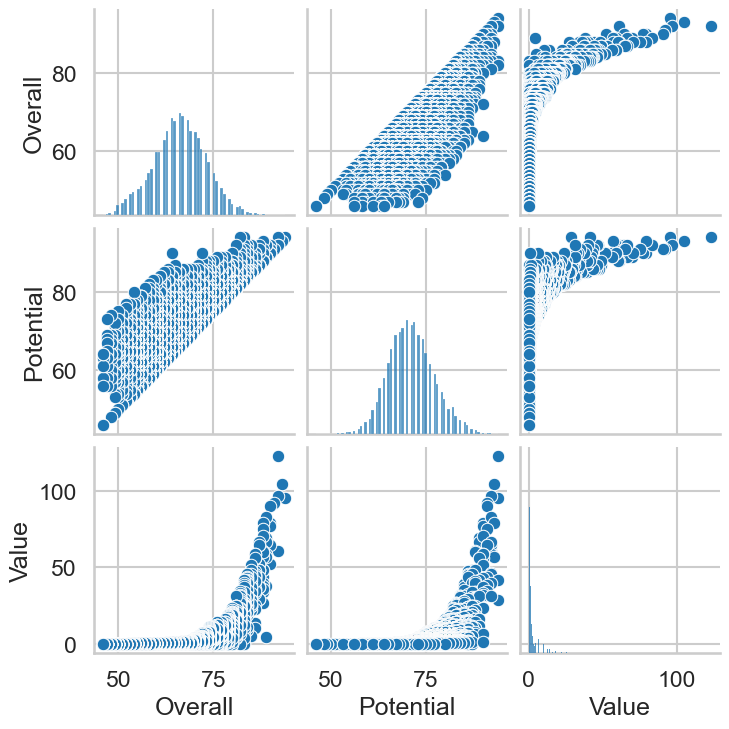

In [31]:
sns.pairplot(footballers[['Overall', 'Potential', 'Value']])

## Faceting

El "faceting" (o división en facetas) es una técnica que permite dividir una visualización en múltiples subgráficos según una o más variables categóricas. La función `FacetGrid` de Seaborn es la herramienta principal para crear este tipo de visualizaciones.

Características principales de `FacetGrid`:
- Crea una matriz de subgráficos basada en variables categóricas
- Permite dividir los datos por filas (`row`), columnas (`col`) o ambas
- Aplica el mismo tipo de visualización a cada subconjunto de datos
- Mantiene las escalas y formatos consistentes entre subgráficos
- Facilita la comparación de patrones entre diferentes categorías

Por ejemplo, podemos crear un gráfico separado para cada posición de jugador, o dividir los datos por club y posición simultáneamente.

La función `FacetGrid` funciona en dos pasos:

1. Primero se crea el objeto grid especificando:
   - Los datos (`data`)
   - Las variables para dividir en filas (`row`) y/o columnas (`col`)
   - Opciones adicionales como el número máximo de columnas (`col_wrap`)

2. Luego se usa el método `map()` para especificar:
   - La función de visualización a aplicar (por ejemplo, `kdeplot`, `scatterplot`, etc.)
   - Las variables a representar en cada subgráfico

Para más detalles, consulta la [documentación oficial de FacetGrid](https://seaborn.pydata.org/generated/seaborn.FacetGrid.html).

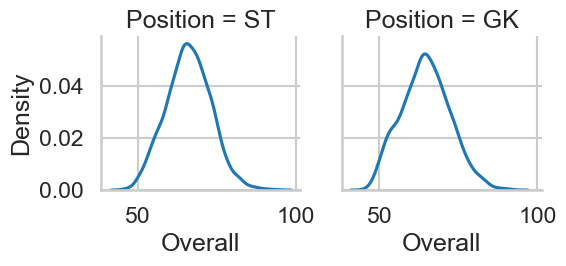

In [32]:
df = footballers[footballers['Position'].isin(['ST', 'GK'])] # De la tabla 'footballers', seleccionamos solo los que tienen como posición ST ('Striker'/'Delantero') y GK ('GoalKeeper'/'Portero')
g = sns.FacetGrid(df, col="Position") # Llamando a la funcion con 2 columnas, genera 2 gráficas
g.map(sns.kdeplot, "Overall") # Plotea la puntuación general de delanteros y porteros en paralelo, para poder compararlas

Otra ventaja es que se puede mapear cada gráfico a una función de Seaborn o Matplotlib. Por ejemplo, podemos ver las distribuciones mediante un boxplot.

Además, también se pueden emplear dos variables categóricas para dividir los datos tanto en filas como en columnas. Por ejemplo, vamos a ver la distribución de las puntuaciones de los jugadores en función de su posición en el campo (portero, delantero, etc.):

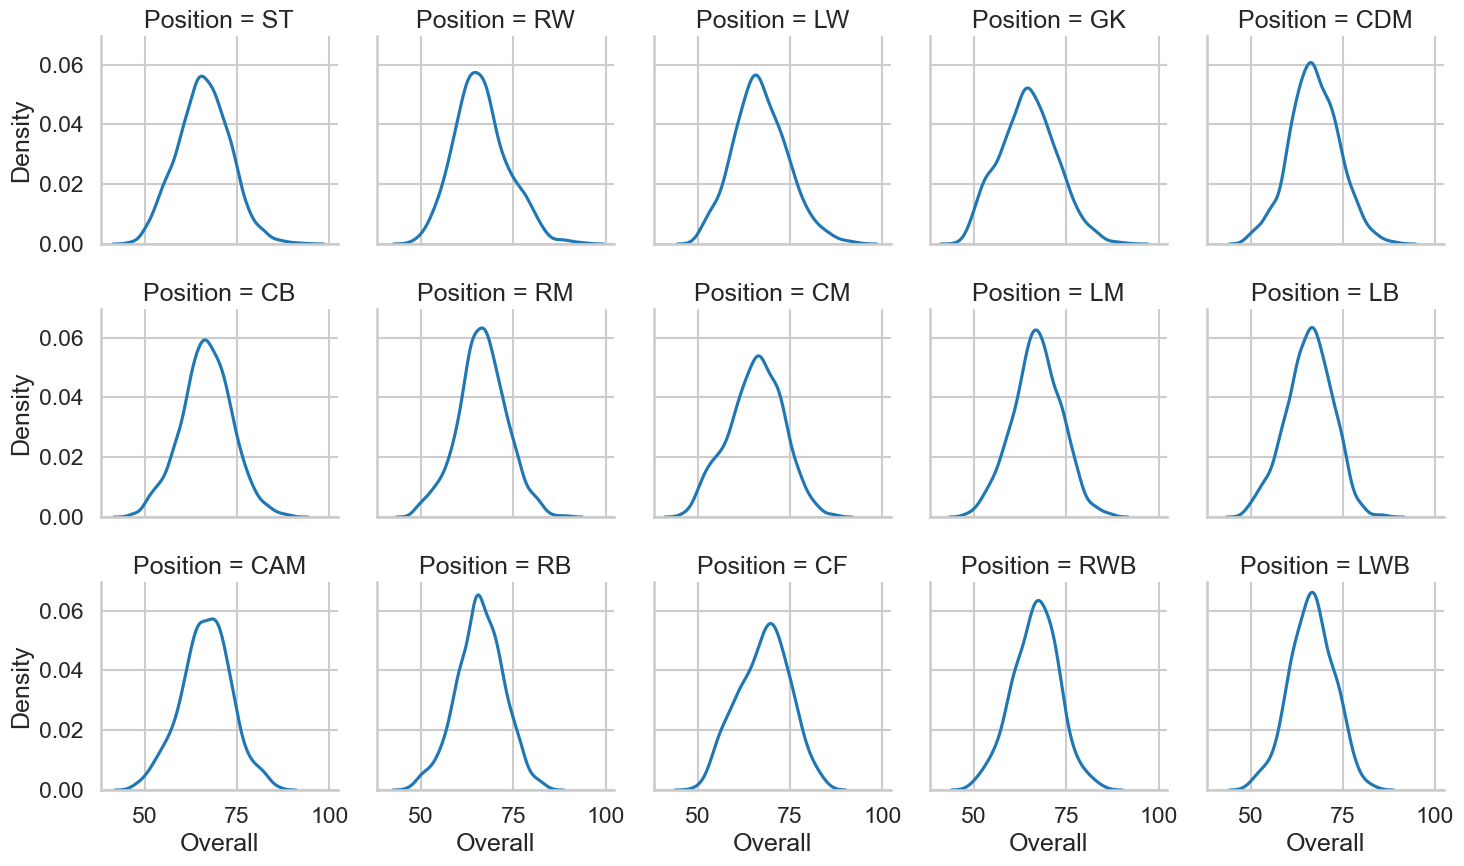

In [33]:
df = footballers

g = sns.FacetGrid(df, col="Position", col_wrap=5)
g.map(sns.kdeplot, "Overall")

También se pueden realizar facetas que incluyan 2 variables por cada cuadro.

Para ello, `FacetGrid` dispone de los parámetros `row` y `col`. 

c:\Users\bbaruque\AppData\Local\miniconda3\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the violinplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


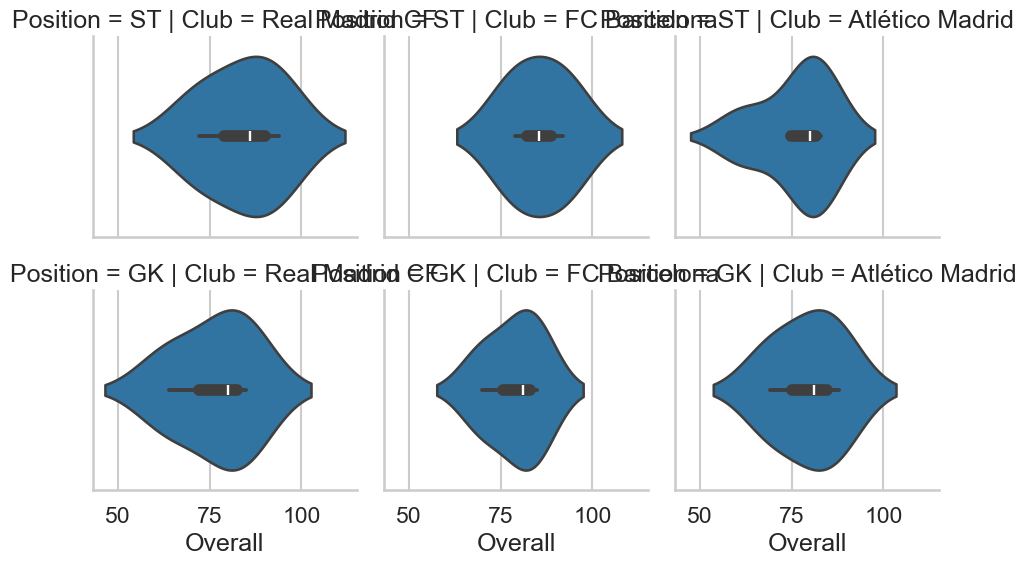

In [34]:
df = footballers[footballers['Position'].isin(['ST', 'GK'])] # De la tabla footballers, se seleccionan solo ST y GK
df = df[df['Club'].isin(['Real Madrid CF', 'FC Barcelona', 'Atlético Madrid'])] # De ellos, solo los que pertenencen a uno de los 3 clubs.

g = sns.FacetGrid(df, row="Position", col="Club") # Se genera la cuadrícula de representación
g.map(sns.violinplot, "Overall") # Se solicita un gráfico de violin en cada apartado.

Para indicar que se desean obtener los diferentes gráficos ordenados de alguna forma, se puede añadir el parámetro `row_order` y `col_order`. Si no se especifica, el orden es aleatorio.

c:\Users\bbaruque\AppData\Local\miniconda3\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the violinplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


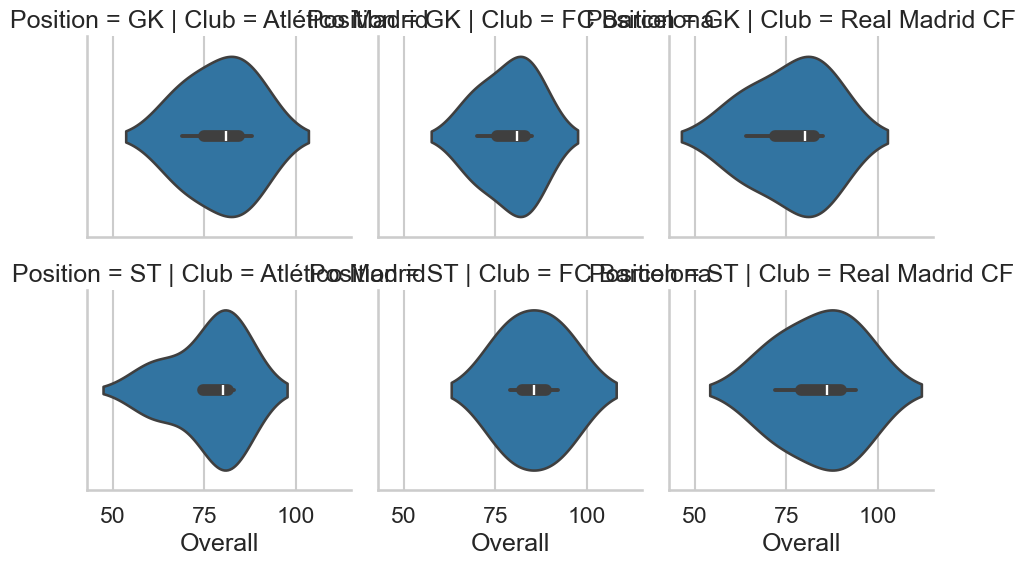

In [35]:
df = footballers[footballers['Position'].isin(['ST', 'GK'])]
df = df[df['Club'].isin(['Real Madrid CF', 'FC Barcelona', 'Atlético Madrid'])]

g = sns.FacetGrid(df, row="Position", col="Club", 
                  row_order=['GK', 'ST'],
                  col_order=['Atlético Madrid', 'FC Barcelona', 'Real Madrid CF'])
g.map(sns.violinplot, "Overall")

### ¿Por qué usar facet?


En resumen, es la forma más sencilla de representar los datos de forma multivariada.

Estableciendo una variable (categórica) como filas y otra (categorica) como columnas, ya tenemos 2 variables establecidas antes de empezar a representar, aumentando las capacidades de visualización.

Es muy sencillo pasar de representar p.ej. un kdeplot a realizar una rejilla con varios de ellos, al necesitar de muy poco código adicional.

Como desventaja, solo podemos realizar estas operaciones con una o dos variables de tipo categórico y con pocos valores diferentes. Además solo se pueden emplear alrededor de 5 dimensiones en la cuadrícula o los valores se vuelven pequeños e ilegibles (o se necesita emplear mucho scroll).


## Función `lmplot`: Gráficos con regresión

La función `lmplot` permite crear gráficos de dispersión con líneas de regresión ajustadas automáticamente.

Además de mostrar la línea de regresión, también muestra el intervalo de confianza del 95% alrededor de la línea (área sombreada).

Es muy útil para:
- Visualizar tendencias en los datos.
- Comparar relaciones entre variables para diferentes grupos.
- Identificar patrones no lineales.
- Detectar valores atípicos respecto a la tendencia general.

Al igual que `FacetGrid`, permite dividir los datos por una o más variables categóricas.

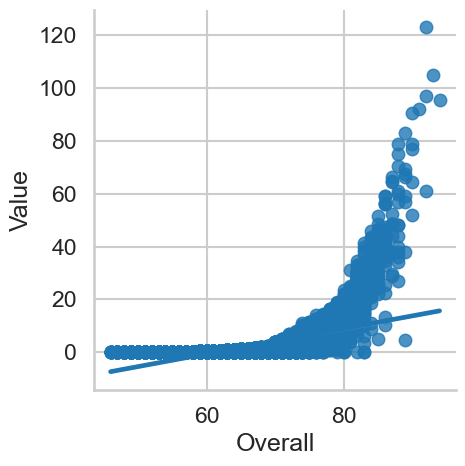

In [36]:
# Ejemplo sencillo de uso de lmplot: relación entre 'Overall' y 'Value'
sns.lmplot(x='Overall', y='Value', data=footballers)

## Personalización de los gráficos

Todos los tipos de gráficos vistos hasta ahora admiten parámetros adicionales para su personalización.

Los más comunes son:
- `hue`: Variable categórica para diferenciar grupos por color
- `col`, `row`: Variables categóricas para dividir en columnas y filas
- `col_wrap`: Número máximo de gráficos por fila (solo si se usa `col`)

Las opciones de personalización son muy amplias y permiten adaptarse a las necesidades específicas de visualización. Por ejemplo, el uso de `col_wrap` es muy útil cuando se tienen muchas categorías y se quiere limitar el ancho de la figura resultante.

c:\Users\bbaruque\AppData\Local\miniconda3\Lib\site-packages\seaborn\regression.py:598: UserWarning: legend_out is deprecated from the `lmplot` function signature. Please update your code to pass it using `facet_kws`.
  warnings.warn(msg, UserWarning)


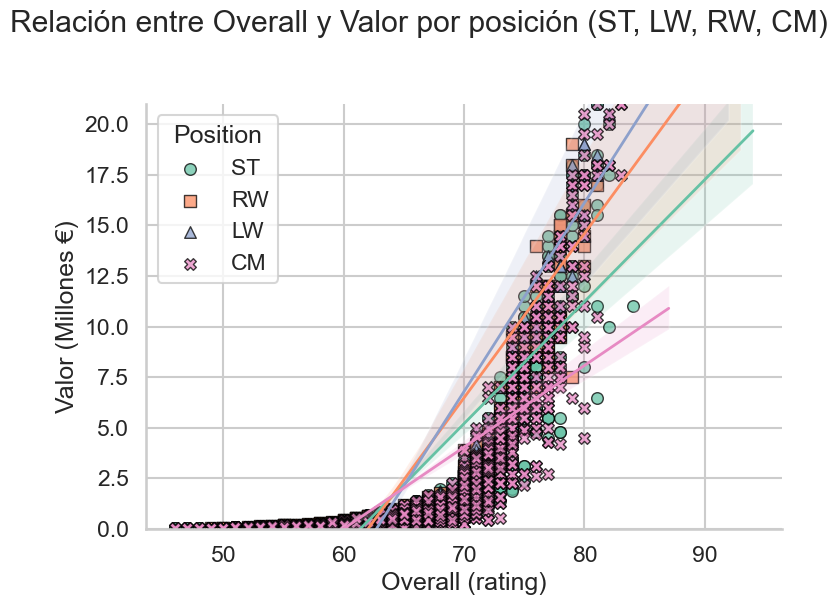

In [37]:
# Ejemplo de personalización: lmplot mostrando la relación Overall vs Value
# para algunas posiciones, con paleta personalizada, marcadores y estilo.
positions = ['ST', 'LW', 'RW', 'CM']
df_plot = footballers[footballers['Position'].isin(positions)].copy()
df_plot = df_plot[df_plot['Value'] > 0]  # eliminar valores 0 para mejor visualización

sns.set_style("whitegrid")
sns.set_context("talk")

g = sns.lmplot(
    x='Overall', y='Value', data=df_plot, hue='Position',
    palette='Set2', markers=['o', 's', '^', 'X'],
    height=6, aspect=1.3, ci=95, legend_out=False,
    scatter_kws={'s': 70, 'alpha': 0.75, 'edgecolor': 'k'},
    line_kws={'linewidth': 2}
)

g.set_axis_labels("Overall (rating)", "Valor (Millones €)")
g.figure.suptitle("Relación entre Overall y Valor por posición (ST, LW, RW, CM)", y=1.02)
# Ajustar límite superior del eje Y para evitar outliers extremos
ymax = df_plot['Value'].quantile(0.98) * 1.05
if df_plot['Value'].max() > ymax:
    g.ax.set_ylim(0, ymax)

g.figure.tight_layout()